In [1]:
from astropy.table import Table
from astropy.coordinates import SkyCoord
import astropy.units as u

catalog = Table.read("PN_catalogue.fits", format="fits")
df = catalog.to_pandas()
for col in df.columns:
    if df[col].dtype == object:
        df[col] = df[col].apply(
            lambda x: x.decode("utf-8") if isinstance(x, bytes) else x)

print(df["gal_name"].unique())
ngc628 = df[(df["gal_name"] == "NGC0628") &(df["type"] == "PN")].copy()
coords = SkyCoord(
    ra=ngc628["RA"].values,
    dec=ngc628["DEC"].values,
    unit=(u.hourangle, u.deg),
    frame="icrs")

ngc628["RAdeg"] = coords.ra.deg
ngc628["DECdeg"] = coords.dec.deg

ngc628 = ngc628.rename(columns={"mOIII": "m5007"})
ngc628.to_csv("NGC628_PN_catalogue.csv", index=False)

print(f"Saved {len(ngc628)} objects")
print(ngc628[["gal_name", "id", "type", "RA", "DEC", "RAdeg", "DECdeg"]].head())

<StringArray>
[ 'IC5332', 'NGC0628', 'NGC1087', 'NGC1300', 'NGC1365', 'NGC1385', 'NGC1433',
 'NGC1512', 'NGC1566', 'NGC1672', 'NGC2835', 'NGC3351', 'NGC3627', 'NGC4254',
 'NGC4303', 'NGC4321', 'NGC4535', 'NGC5068', 'NGC7496']
Length: 19, dtype: str
Saved 139 objects
   gal_name  id type            RA            DEC      RAdeg     DECdeg
63  NGC0628   1   PN  01h36m43.31s  +15d47m18.15s  24.180458  15.788375
64  NGC0628   2   PN  01h36m43.35s  +15d47m18.35s  24.180625  15.788431
65  NGC0628   3   PN  01h36m41.29s  +15d47m04.41s  24.172042  15.784558
66  NGC0628   4   PN  01h36m39.96s  +15d47m02.64s  24.166500  15.784067
67  NGC0628   5   PN  01h36m41.37s  +15d46m58.31s  24.172375  15.782864


oiii/halpha 0.5745334179110725 55.60779141231331
m5007 25.509007167846676 27.986442619872548


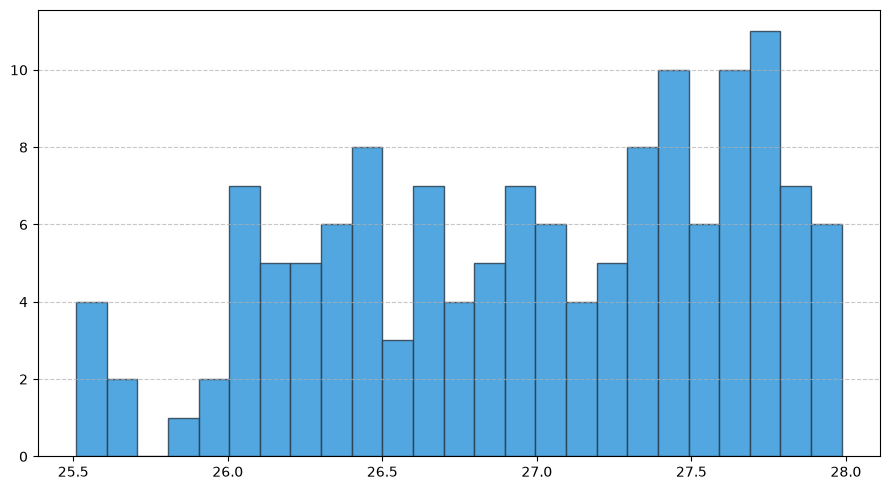

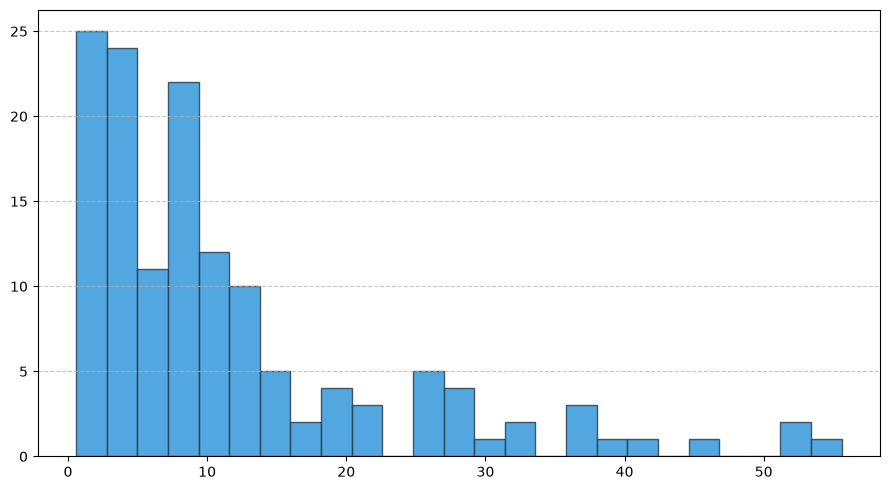

In [5]:
import numpy as np
import matplotlib.pyplot as plt

oiii_halpha = 10**ngc628["logOIII/Ha"]
m5007 = ngc628["m5007"]

print("oiii/halpha", np.min(oiii_halpha), np.max(oiii_halpha))
print("m5007", np.min(m5007), np.max(m5007))

plt.figure(figsize=(9, 5))
plt.hist(m5007, bins=25,color='#3498db', edgecolor='#2c3e50', alpha=0.85, density=False)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
plt.figure(figsize=(9, 5))
plt.hist(oiii_halpha, bins=25,color='#3498db', edgecolor='#2c3e50', alpha=0.85, density=False)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()